# Next-Token Prediction Transformer with Self-Attention

This notebook demonstrates how to build and train a basic Transformer-based Next-Token Prediction model from scratch using PyTorch. We will:
1. Prepare and tokenize text data.
2. Build a simplified Self-Attention mechanism and Transformer Block.
3. Train the model while logging token usage and metrics.
4. Visualize training performance.
5. Generate text completions using our trained model.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import math

torch.manual_seed(42)
np.random.seed(42)

## 1. Data Preparation & Toy Vocabulary
We will define a simple corpus, build a character-level tokenizer, and prepare training pairs of input sequences and shifted target sequences (next-tokens).

In [2]:
corpus = """system training is simple.
transformers are powerful.
self attention helps us predict the next token easily.
learning deep learning is fun!"""

chars = sorted(list(set(corpus)))
vocab_size = len(chars)
char_to_ix = {ch: i for i, ch in enumerate(chars)}
ix_to_char = {i: ch for i, ch in enumerate(chars)}

print(f"Vocabulary size: {vocab_size} characters.")
print(f"Vocabulary: {''.join(chars)}")

def encode(text):
    return [char_to_ix[c] for c in text]

def decode(indices):
    return "".join([ix_to_char[i] for i in indices])

Vocabulary size: 25 characters.
Vocabulary: 
 !.acdefghiklmnoprstuwxy


## 2. Model Architecture: Basic Self-Attention & Transformer
Here we implement standard Query, Key, Value mappings and scaled dot-product self-attention with causal masking (to prevent looking at future tokens).

In [3]:
class SimpleSelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)
        self.embed_dim = embed_dim

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)  # (B, T, C)
        k = self.key(x)    # (B, T, C)
        v = self.value(x)  # (B, T, C)

        # Scaled dot-product scores
        scores = torch.bmm(q, k.transpose(1, 2)) / math.sqrt(self.embed_dim)  # (B, T, T)

        # Causal mask to ensure we only attend to past and current elements
        mask = torch.tril(torch.ones(T, T)).to(x.device)
        scores = scores.masked_fill(mask == 0, float('-inf'))

        weights = F.softmax(scores, dim=-1)  # (B, T, T)
        out = torch.bmm(weights, v)          # (B, T, C)
        return out

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.attn = SimpleSelfAttention(embed_dim)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim)
        )
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        # Residual connections with LayerNorm
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

class CharacterTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim, max_seq_len):
        super().__init__()
        self.token_embeddings = nn.Embedding(vocab_size, embed_dim)
        self.position_embeddings = nn.Embedding(max_seq_len, embed_dim)
        self.blocks = nn.Sequential(
            TransformerBlock(embed_dim),
            TransformerBlock(embed_dim)
        )
        self.ln_f = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size)
        self.max_seq_len = max_seq_len

    def forward(self, idx):
        B, T = idx.shape
        tok_emb = self.token_embeddings(idx) # (B, T, embed_dim)
        pos_emb = self.position_embeddings(torch.arange(T, device=idx.device)) # (T, embed_dim)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.head(x) # (B, T, vocab_size)
        return logits

## 3. Training Loop with Metrics and Token Tracking

In [4]:
# Hyperparameters
embed_dim = 64
seq_len = 16
epochs = 150
lr = 0.005

# Instantiate Model
model = CharacterTransformer(vocab_size, embed_dim, seq_len)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

# Prepare training datasets from our toy corpus
encoded_corpus = encode(corpus)
X, Y = [], []
for i in range(len(encoded_corpus) - seq_len):
    X.append(encoded_corpus[i : i + seq_len])
    Y.append(encoded_corpus[i + 1 : i + seq_len + 1])

X = torch.tensor(X, dtype=torch.long)
Y = torch.tensor(Y, dtype=torch.long)

# Tracking logs
loss_history = []
tokens_processed_history = []
total_tokens_processed = 0

# Training loop
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(X)
    loss = criterion(logits.view(-1, vocab_size), Y.view(-1))
    loss.backward()
    optimizer.step()

    # Count tokens processed: Batch Size * Sequence Length
    current_tokens = X.numel()
    total_tokens_processed += current_tokens

    loss_history.append(loss.item())
    tokens_processed_history.append(total_tokens_processed)

    if (epoch + 1) % 30 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d} | Loss: {loss.item():.4f} | Cumulative Tokens Processed: {total_tokens_processed:,}")

Epoch 001 | Loss: 3.4786 | Cumulative Tokens Processed: 1,968
Epoch 030 | Loss: 0.5346 | Cumulative Tokens Processed: 59,040
Epoch 060 | Loss: 0.1380 | Cumulative Tokens Processed: 118,080
Epoch 090 | Loss: 0.1258 | Cumulative Tokens Processed: 177,120
Epoch 120 | Loss: 0.1316 | Cumulative Tokens Processed: 236,160
Epoch 150 | Loss: 0.1232 | Cumulative Tokens Processed: 295,200


## 4. Performance Metrics and Token Usage Visualizations

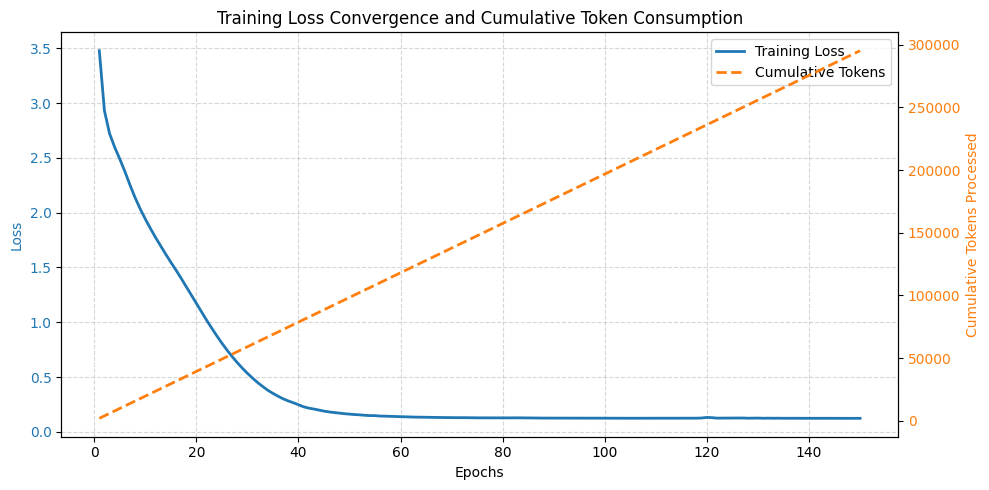

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot loss profile
color = 'tab:blue'
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss', color=color)
line1 = ax1.plot(range(1, epochs + 1), loss_history, color=color, label='Training Loss', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot cumulative token usage
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Cumulative Tokens Processed', color=color)
line2 = ax2.plot(range(1, epochs + 1), tokens_processed_history, color=color, linestyle='--', label='Cumulative Tokens', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

# Merge legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('Training Loss Convergence and Cumulative Token Consumption')
fig.tight_layout()
plt.show()

## 5. Model Inference (Generative Completion)
Let's test our next-token predictor model by giving it a starting prompt and allowing it to generate the subsequent tokens.

In [6]:
def generate_text(prompt, length=40):
    model.eval()
    with torch.no_grad():
        current_text = prompt
        for _ in range(length):
            encoded_input = encode(current_text[-seq_len:])
            if len(encoded_input) < seq_len:
                encoded_input = [char_to_ix[' ']] * (seq_len - len(encoded_input)) + encoded_input

            input_tensor = torch.tensor([encoded_input], dtype=torch.long)
            logits = model(input_tensor)

            next_token_logits = logits[0, -1, :]
            probs = F.softmax(next_token_logits, dim=-1)

            next_index = torch.multinomial(probs, num_samples=1).item()
            current_text += ix_to_char[next_index]
    return current_text

prompt_test = "system training"
completed = generate_text(prompt_test, length=50)
print(f"Prompt: '{prompt_test}'")
print(f"Completion: '{completed}'")

Prompt: 'system training'
Completion: 'system training is simple.
transformers are powerful.
self attent'
